# **COMP 2211 - Introduction to Artificial Intelligence**
# Lab 6: Speech Command Recognition with Multilayer Perceptron

## Introduction
Speech recognition is one of the most visible applications of Artificial Intelligence. When you talk to a voice assistant, dictate a message, or give a command to a smart device, the system must transform a raw audio signal into a machine-readable representation before making a prediction. In this lab, you will explore this idea through a compact **speech command recognition** task, where short audio clips are converted into numerical features and then classified by a **Multilayer Perceptron (MLP)**.


---
### Background
This lab introduces an **audio modality**. A raw waveform cannot be fed directly into a small MLP in a natural way, so we first extract a fixed-length feature vector from each audio clip. In this lab, the feature vector is built from [**MFCC statistics**](https://en.wikipedia.org/wiki/Mel-frequency_cepstrum), which provide a compact summary of how speech changes over time.

### Objective
Your goal is to build a complete speech classification pipeline. You will load audio samples, convert them into fixed-length 1D feature vectors, normalize the data, and later use these processed features to train and evaluate an MLP classifier. By the end of the lab, you should understand how an audio classification problem can be simplified into a structured machine learning workflow.

### Dataset Description
You will work with a balanced subset of the Speech Commands dataset. It contains 7,200 one-second audio clips (900 per class) from 8 commands: `down`, `go`, `left`, `no`, `right`, `stop`, `up`, and `yes`. Each clip is a mono 16 kHz `.wav` file.

| Item | Role | Type | Description |
| :--- | :--- | :--- | :--- |
| **waveform** | Raw Input | Audio | A short speech clip stored as a `.wav` file. |
| **MFCC feature vector** | Processed Feature | Continuous | A fixed-length 1D summary vector extracted from the waveform. |
| **command label** | Target | Categorical | One of 8 spoken commands: `down`, `go`, `left`, `no`, `right`, `stop`, `up`, `yes`. |

After loading the dataset, each audio clip will be converted into a feature vector of shape `(D,)`, and the full dataset will eventually take the form:
- `X` of shape `(N, D)`
- `y` of shape `(N,)`

### Task Overview
In this lab, you will build a complete speech command recognition pipeline with an MLP. The tasks follow the normal machine learning workflow: prepare the data, define the model, design a custom metric, and train the model.

1. **Task 1: Data Processing and Batching**  
   Build a `DataLoader` class to load speech clips, convert them into MFCC-based 1D vectors, split the dataset, normalize the features, and create batched datasets.
2. **Task 2: Model Building**  
   Implement a `SpeechRecognizer` model using fully connected layers. The model should take one feature vector as input and output probabilities over 8 speech commands.
3. **Task 3: Customized Macro F1 Metric**  
   Implement a stateful Macro F1 metric so that Keras can track class-balanced performance during training and validation.
4. **Task 4: Model Training**  
   Instantiate the model, compile it with the required loss and metrics, inspect its structure and size, and train it with validation monitoring.

After training, you will use the provided evaluation and plotting code to inspect validation performance and learning curves for further model tuning.

### Dataset attribution
The audio clips are derived from Pete Warden's [Speech Commands dataset](https://arxiv.org/abs/1804.03209). This lab uses a balanced eight-command subset prepared for COMP 2211.


In [1]:
from pathlib import Path
import shutil
import zipfile
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, optimizers, losses
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

try:
    from IPython.display import Audio, display
except ImportError:  # Allows the exported .py file to be imported by ZINC
    Audio = display = None

if __name__ == '__main__':
    from google.colab import drive
    drive.mount("/content/drive")

    # Download data.zip from the Lab 6 webpage and place it at this path.
    zip_path = Path("/content/drive/MyDrive/COMP2211/Lab6/data.zip")
    local_zip_path = Path("/content/data.zip")
    data_path = Path("/content/data")

    if not zip_path.exists():
        raise FileNotFoundError(
            f"Cannot find {zip_path}. Download data.zip from the Lab 6 webpage "
            "and upload it to MyDrive/COMP2211/Lab6/."
        )

    if not local_zip_path.exists():
        shutil.copy(zip_path, local_zip_path)

    if not data_path.exists():
        with zipfile.ZipFile(local_zip_path, "r") as zip_ref:
            zip_ref.extractall("/content")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Playground: Listen to Speech Commands

Before converting audio clips into numerical features, let us listen to a few raw `.wav` files from different command classes. This gives you an intuitive sense of what the model will learn from: short spoken commands with different speakers, accents, and background conditions.

The code below selects one audio clip from several classes and displays an audio player for each clip.

In [2]:
if __name__ == '__main__':
    if Audio is None:
        raise ImportError("IPython is required for the audio playground.")

    sample_labels = ["yes", "no", "up", "down"]

    for label in sample_labels:
        wav_path = sorted((data_path / label).glob("*.wav"))[0]
        print("Command:", label)
        display(Audio(filename=str(wav_path)))

Command: yes


Command: no


Command: up


Command: down


## Task 1: Data Processing and Batching

In this task, you will implement a `DataLoader` class to prepare the speech dataset for later model training. The overall goal is to convert raw audio clips into clean numerical inputs that an MLP can learn from.

### Task 1.1: Processing
The dataset is stored in the `data/` folder. Each subfolder corresponds to one spoken command class, and each `.wav` file inside that folder is one training example. Split the 7,200 examples into 6,400 training examples and 800 validation examples using `test_size=1/9` and `random_state=self.seed`. Then normalize both splits using only the training-set mean and standard deviation. NumPy's default `ddof=0` is required.

### Task 1.2: Batching
After normalization, the final step is to turn the training and validation arrays into batched TensorFlow datasets. This lets later training code receive `train` and `val` directly from `batch_data(...)`.

---
**Suggested functions:**
- `np.mean`: https://numpy.org/doc/stable/reference/generated/numpy.mean.html
- `np.std`: https://numpy.org/doc/stable/reference/generated/numpy.std.html
- `train_test_split` : https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html
- `tf.data.Dataset.from_tensor_slices` : https://www.tensorflow.org/api_docs/python/tf/data/Dataset#from_tensor_slices
- `tf.data.Dataset.batch` : https://www.tensorflow.org/api_docs/python/tf/data/Dataset#batch


In [3]:
class DataLoader:
    """
    Loads, splits, normalizes, and batches the speech dataset.

    Args:
        batch_size: int. Number of samples in each batch.
        seed: int. Random seed used in train-validation split.
        X_train: np.ndarray with shape (N_train, D). Training data.
        y_train: np.ndarray with shape (N_train, ). Training labels.
        X_val: np.ndarray with shape (N_val, D). Validation data.
        y_val: np.ndarray with shape (n_val, ). Validation labels.
    """
    def __init__(self, batch_size: int, seed: int):
        self.batch_size = batch_size
        self.seed = seed
        self.X_train = None
        self.y_train = None
        self.X_val = None
        self.y_val = None

    # ====================================================
    # NOTE: This is a helper function, do not modify it
    # ====================================================
    @staticmethod
    @tf.function(input_signature=[
        tf.TensorSpec(shape=[None], dtype=tf.float32),
        tf.TensorSpec(shape=[], dtype=tf.int32),
    ])
    def _audio_to_mfcc_features(
        waveform: tf.Tensor,
        sample_rate: tf.Tensor,
    ) -> tf.Tensor:
        """
        Converts one waveform into a fixed-length 1D MFCC feature vector.

        Args:
            waveform: tf.Tensor. Audio waveform tensor of shape (num_samples,).
            sample_rate: tf.Tensor. Audio sample rate tensor.

        Returns:
            feature: tf.Tensor. 1D tensor of shape (26,).
        """
        waveform = tf.cast(tf.squeeze(waveform), tf.float32)
        num_mfcc = 13
        frame_length = 640
        frame_step = 320
        fft_length = 1024

        stft = tf.signal.stft(
            waveform,
            frame_length=frame_length,
            frame_step=frame_step,
            fft_length=fft_length,
        )
        spectrogram = tf.abs(stft)

        mel_weight_matrix = tf.signal.linear_to_mel_weight_matrix(
            num_mel_bins=40,
            num_spectrogram_bins=513,
            sample_rate=16000.0,
            lower_edge_hertz=20.0,
            upper_edge_hertz=8000.0,
        )

        mel_spectrogram = tf.matmul(tf.square(spectrogram), mel_weight_matrix)
        log_mel_spectrogram = tf.math.log(mel_spectrogram + 1e-6)
        mfcc = tf.signal.mfccs_from_log_mel_spectrograms(log_mel_spectrogram)[..., :num_mfcc]
        mfcc_mean = tf.reduce_mean(mfcc, axis=0)
        mfcc_std = tf.math.reduce_std(mfcc, axis=0)
        feature = tf.concat([mfcc_mean, mfcc_std], axis=0)
        return feature


    def load_data(self, data_dir: str) -> tuple[list[np.ndarray], list[int]]:
        """
        Loads the full dataset and converts all audio clips into 1D MFCC feature vectors.

        Args:
            data_dir: str. Path to the dataset folder.

        Returns:
            features: list[np.ndarray]. Feature vectors extracted from all audio clips.
            labels: list[int]. Integer labels aligned with the feature vectors.
        """
        label_map = {
            'down': 0,
            'go': 1,
            'left': 2,
            'no': 3,
            'right': 4,
            'stop': 5,
            'up': 6,
            'yes': 7,
        }

        features = []
        labels = []

        for label_dir in sorted(Path(data_dir).iterdir()):
            if not label_dir.is_dir():
                continue
            for wav_path in sorted(label_dir.glob('*.wav')):
                audio_binary = tf.io.read_file(str(wav_path))
                waveform, sample_rate = tf.audio.decode_wav(audio_binary, desired_channels=1)
                waveform = tf.squeeze(waveform, axis=-1)
                feature = DataLoader._audio_to_mfcc_features(waveform, sample_rate)
                features.append(feature.numpy())
                labels.append(label_map[label_dir.name])

        return features, labels


    def process_data(self, X: list[np.ndarray], y: list[int]) -> None:
        """
        Splits the processed data into training and validation sets, then normalizes both splits.

        Args:
            X: list[np.ndarray]. Feature vectors extracted from the audio clips.
            y: list[int]. Integer labels aligned with the feature vectors.
        """
        ## TODO ====================================================================
        # 1. Convert `X` and `y` into np.ndarray (X & y correspondingly)
        # 2. Split X and y separately, with the split ratio 8(train) : 1(val)
        # 3. Calculate the mean and std for `self.X_train`
        # 4. Apply normalization to self.X_train and self.X_val (add 1e-8 to prevent division by zero)
        # NOTE: Store the data back to self.X_train, self.X_val, self.y_train, self.y_val
        ## =========================================================================

        X_raw = np.array(X,dtype=np.float32)         # shape (7200, 26)
        y_raw = np.array(y,dtype=int)                         # shape (7200,)
        X_train, X_val, self.y_train, self.y_val = train_test_split(X_raw, y_raw, test_size=1/9, random_state=self.seed)
        self.X_train = (X_train - X_train.mean(axis=0)) / (X_train.std(axis=0,ddof=0) + 1e-8)
        self.X_val = (X_val - X_train.mean(axis=0)) / (X_train.std(axis=0,ddof=0) + 1e-8)



    def batch_data(self) -> tuple[tf.data.Dataset, tf.data.Dataset]:
        """
        Convert training and validation arrays into batched TensorFlow datasets.

        Returns:
            train: tf.data.Dataset. Batched training dataset.
            val: tf.data.Dataset. Batched validation dataset.
        """
        ## TODO ===================================================================
        # 1. Pair self.X_train with self.y_train as a TensorFlow dataset
        # 2. Pair self.X_val with self.y_val as a TensorFlow dataset
        # 3. Batch both datasets using self.batch_size
        ## ========================================================================
        train = tf.data.Dataset.from_tensor_slices((self.X_train,self.y_train)).shuffle(buffer_size=len(self.X_train),seed=self.seed)
        val = tf.data.Dataset.from_tensor_slices((self.X_val,self.y_val)).shuffle(buffer_size=len(self.X_train),seed=self.seed)
        train = train.batch(self.batch_size)
        val = val.batch(self.batch_size)

        return train, val

After finishing `DataLoader`, you can run the code below to see whether it works smoothly.  
The standard output should be (if `self.batch_size` = 32):

```text
=============================================
Process Data Check
=============================================
train mean[:5]      : [-47.123661, 8.540713, -0.085749, 1.368846, -1.270643]
train std[:5]       : [21.114214, 4.924758, 2.868526, 1.971217, 1.828290]
train norm mean[:5] : [-0.000001, -0.000003, 0.000000, 0.000001, -0.000001]
train norm std[:5]  : [0.999999, 1.000000, 1.000001, 1.000000, 0.999999]
val norm mean[:5]   : [0.018830, 0.023129, 0.059524, -0.033125, -0.014524]
val norm std[:5]    : [0.965352, 1.004909, 0.966955, 0.989480, 0.966550]

=============================================
Data Shape Summary
=============================================
X_train shape      : (6400, 26)
X_val shape        : (800, 26)
y_train shape      : (6400,)
y_val shape        : (800,)
train batch X shape: (32, 26)
train batch y shape: (32,)
val batch X shape  : (32, 26)
val batch y shape  : (32,)
```

**Note:** The seed of the `DataLoader` should be 42, but you can modify the batch size to gain better model performance.


In [4]:
if __name__ == '__main__':
    data_loader = DataLoader(batch_size=32, seed=42)
    features, labels = data_loader.load_data(data_path)
    data_loader.process_data(features, labels)
    train, val = data_loader.batch_data()

    X = np.array(features)
    y = np.array(labels)
    expected_X_train, expected_X_val, expected_y_train, expected_y_val = train_test_split(
        X, y, test_size=1 / 9, random_state=data_loader.seed
    )
    expected_mean = np.mean(expected_X_train, axis=0)
    expected_std = np.std(expected_X_train, axis=0) + 1e-8
    expected_X_train = (expected_X_train - expected_mean) / expected_std
    expected_X_val = (expected_X_val - expected_mean) / expected_std

    def format_vector(values: np.ndarray) -> str:
        return "[" + ", ".join(f"{float(value):.6f}" for value in values) + "]"

    for train_features, train_labels in train.take(1): pass
    for val_features, val_labels in val.take(1): pass

    print("=" * 45)
    print("Process Data Check")
    print("=" * 45)
    print(f"train mean[:5]      : {format_vector(np.round(expected_mean[:5], 6))}")
    print(f"train std[:5]       : {format_vector(np.round(expected_std[:5], 6))}")
    print(f"train norm mean[:5] : {format_vector(np.round(np.mean(data_loader.X_train, axis=0)[:5], 6))}")
    print(f"train norm std[:5]  : {format_vector(np.round(np.std(data_loader.X_train, axis=0)[:5], 6))}")
    print(f"val norm mean[:5]   : {format_vector(np.round(np.mean(data_loader.X_val, axis=0)[:5], 6))}")
    print(f"val norm std[:5]    : {format_vector(np.round(np.std(data_loader.X_val, axis=0)[:5], 6))}")
    print()
    print("=" * 45)
    print("Data Shape Summary")
    print("=" * 45)
    print(f"X_train shape      : {data_loader.X_train.shape}")
    print(f"X_val shape        : {data_loader.X_val.shape}")
    print(f"y_train shape      : {data_loader.y_train.shape}")
    print(f"y_val shape        : {data_loader.y_val.shape}")
    print(f"train batch X shape: {train_features.shape}")
    print(f"train batch y shape: {train_labels.shape}")
    print(f"val batch X shape  : {val_features.shape}")
    print(f"val batch y shape  : {val_labels.shape}")

Process Data Check
train mean[:5]      : [-47.123661, 8.540713, -0.085749, 1.368846, -1.270643]
train std[:5]       : [21.114214, 4.924758, 2.868526, 1.971217, 1.828290]
train norm mean[:5] : [-0.000001, -0.000003, 0.000000, 0.000001, -0.000001]
train norm std[:5]  : [0.999999, 1.000000, 1.000001, 1.000000, 0.999999]
val norm mean[:5]   : [0.018830, 0.023129, 0.059524, -0.033125, -0.014524]
val norm std[:5]    : [0.965352, 1.004909, 0.966955, 0.989480, 0.966550]

Data Shape Summary
X_train shape      : (6400, 26)
X_val shape        : (800, 26)
y_train shape      : (6400,)
y_val shape        : (800,)
train batch X shape: (32, 26)
train batch y shape: (32,)
val batch X shape  : (32, 26)
val batch y shape  : (32,)


## Task 2: Model Building

In this task, you will implement a `SpeechRecognizer` model for classifying speech commands. Your goal is to implement a compact neural network by inheriting from `tf.keras.Model`. This keeps the model definition clean and makes the architecture explicit.


---
**How Keras subclassing works**

`SpeechRecognizer(tf.keras.Model)` creates a custom Keras model by inheriting from the base `tf.keras.Model` class. The base class already knows how to work with `compile(...)`, `fit(...)`, `evaluate(...)`, saving, and trainable variables. Your job is to fill in the model-specific parts:
- `__init__(...)` defines the layers and stores them as attributes.
- `call(...)` describes how one batch of inputs flows through those layers.

When you later call `model(x)` or use `model.fit(...)`, Keras automatically runs your overridden `call(...)` method behind the scenes. This is why the method name and its input/output behavior must match the Keras pattern shown in the documentation.


---
**Suggested TensorFlow Components**
- `tf.keras.Model` : https://www.tensorflow.org/api_docs/python/tf/keras/Model
- `tf.keras.layers.Dense` : https://www.tensorflow.org/api_docs/python/tf/keras/layers/Dense
- `tf.keras.layers.Dropout` : https://www.tensorflow.org/api_docs/python/tf/keras/layers/Dropout
- `tf.keras.layers.LayerNormalization` : https://www.tensorflow.org/api_docs/python/tf/keras/layers/LayerNormalization
- `tf.keras.layers.BatchNormalization` : https://www.tensorflow.org/api_docs/python/tf/keras/layers/BatchNormalization

---
**Suggested Model Structures**
- **Narrow and deep models:** Use more hidden layers, but keep each layer relatively small. This can help the model learn several stages of transformation, but it may also become harder to train if the network is too deep.
- **Short and wide models:** Use fewer hidden layers, but give each layer more neurons. This often works well for compact tabular-like feature vectors such as our MFCC summary features.
- **Regularized models:** Add `Dropout` when the training accuracy is much higher than the validation accuracy. Dropout is usually placed after an activation layer to reduce overfitting.

    > The `training` argument is a Boolean mode flag: `True` during training and `False` during validation or inference. In `call(self, inputs, training=False)`, forward that flag to Dropout, for example `x = self.dropout(x, training=training)`. The right-hand `training` is the Boolean argument of `call`, not a string or a fixed value. Keras sets the mode when running `fit`, `evaluate`, and `predict`; do not hard-code `True` or `False` inside `call`. See the [Keras Dropout documentation](https://www.tensorflow.org/api_docs/python/tf/keras/layers/Dropout).
- **Normalized models:** Add `LayerNormalization` or `BatchNormalization` when training is unstable, or validation performance improves slowly. There are two options: **Pre-Normalization**(before `Dense()`) and **Post-Normalization**(after `Dense()`).

A good model should be large enough to learn useful command patterns, but not so large that it simply memorizes the training set.

In [5]:
class SpeechRecognizer(tf.keras.Model):
    """
    A compact MLP for speech command classification.

    Args:
        input_dim: int. Number of input features in each sample.
        num_classes: int. Number of output classes.
    """
    def __init__(self, input_dim: int, num_classes: int):
        # TODO ================================================================
        # Build your model. The architecture is arbitrary, no standard answer
        # =====================================================================
        super().__init__()
        self.BASE_DROPOUT = 0.3
        self.BASE_DENSE_DIM = input_dim*10
        self.dense1 = tf.keras.layers.Dense(int(self.BASE_DENSE_DIM),activation="relu")
        self.dropout1 = tf.keras.layers.Dropout(self.BASE_DROPOUT)
        self.dense2 = tf.keras.layers.Dense(int(self.BASE_DENSE_DIM*0.5),activation="relu")
        self.dropout2 = tf.keras.layers.Dropout(self.BASE_DROPOUT*0.5)
        self.output_layer = tf.keras.layers.Dense(num_classes,activation="softmax")

    def call(self, inputs: tf.Tensor, training: bool = False) -> tf.Tensor:
        """
        Runs the forward pass of the MLP.

        Args:
            inputs: tf.Tensor. Input batch of shape (batch_size, input_dim).
            training: bool. Whether the model is in training mode.

        Returns:
            outputs: tf.Tensor. Predicted class probabilities of shape (batch_size, num_classes).
        """
        # TODO ================================================================
        # Build your data flow inside the model. Use the structure above
        # =====================================================================
        outputs = self.dense1(inputs)
        outputs = self.dropout1(outputs,training=training)
        outputs = self.dense2(outputs)
        outputs = self.dropout2(outputs,training=training)
        outputs = self.output_layer(outputs)
        return outputs

## Task 3: Customized F1 Metric Implementation

In this task, you will convert F1-Score into a TensorFlow standard evaluation metric to record model performance while training. Be careful: your custom F1 metric should be **stateful across the full epoch**, rather than computing F1 independently for each batch.


---
**How Keras metric overriding works**

`MacroF1Score(tf.keras.metrics.Metric)` creates a custom metric by inheriting from the base `tf.keras.metrics.Metric` class. Keras expects a metric object to keep its own state and update that state batch by batch:
- `__init__(...)` creates persistent state variables, such as `self.cm`.
- `update_state(...)` is called once for each batch and should update the stored state.
- `result(...)` converts the stored state into the number Keras reports.
- `reset_state(...)` clears the stored state before a new epoch or evaluation run.

These methods are called by Keras automatically during `fit(...)` and `evaluate(...)`. Implementing them correctly is important because a broken metric can make training progress look misleading even when the model code runs without errors.

---

> Why Macro F1?  
> Accuracy tells us how many predictions are correct overall, but it does not always show whether the model performs well on every class. In speech recognition, some commands may be easier than others. A **Macro F1 Score** computes F1 for each class separately and then averages them, so every class contributes equally.

### Task 3.1: Updating the Metric State
Keras will call `update_state(...)` once for each batch during training and validation. In this function, your job is to update `self.cm`, the confusion matrix stored inside the metric object.

### Task 3.2: Computing the Metric Result
Keras will call `result(...)` when it needs the current Macro F1 value. In this function, your job is to compute Macro F1 from the accumulated confusion matrix `self.cm`.

---
**Suggested TensorFlow Components**
- `tf.keras.metrics.Metric` : https://www.tensorflow.org/api_docs/python/tf/keras/metrics/Metric
- `tf.argmax` : https://www.tensorflow.org/api_docs/python/tf/math/argmax
- `tf.math.confusion_matrix` : https://www.tensorflow.org/api_docs/python/tf/math/confusion_matrix
- `tf.linalg.diag_part` : https://www.tensorflow.org/api_docs/python/tf/linalg/diag_part
- `tf.reduce_sum` : https://www.tensorflow.org/api_docs/python/tf/math/reduce_sum
- `tf.reduce_mean` : https://www.tensorflow.org/api_docs/python/tf/math/reduce_mean
- `tf.zeros` : https://www.tensorflow.org/api_docs/python/tf/zeros
- `assign_add` : https://www.tensorflow.org/api_docs/python/tf/Variable#assign_add


In [6]:
class MacroF1Score(tf.keras.metrics.Metric):
    """
    Computes macro F1 score across one full epoch.

    Args:
        num_classes: int. Number of classes in the classification task.
        name: str. Name of the metric.
    """
    def __init__(self, num_classes: int, name: str = "f1_score", **kwargs):
        super().__init__(name=name, **kwargs)
        self.num_classes = num_classes
        self.cm = self.add_weight(
            name="confusion_matrix",
            shape=(num_classes, num_classes),
            initializer="zeros",
        )

    def update_state(self, y_true: tf.Tensor, y_pred: tf.Tensor, sample_weight=None) -> None:
        """
        Updates the confusion matrix using one batch of labels and predictions.

        Args:
            y_true: tf.Tensor. True labels of shape (batch_size,).
            y_pred: tf.Tensor. Predicted probabilities of shape (batch_size, num_classes).
            sample_weight: Optional sample weights. Not used in this lab.
        """
        # TODO ============================================================================================
        # 1. Convert predicted probabilities to predicted class labels
        # 2. Build the confusion matrix for this batch using `tf.math.confusion_matrix`
        # 3. Add this batch confusion matrix to the stored epoch confusion matrix using `assign_add`
        # NOTE: Data type of your batch confusion matrix should be tf.float32
        # =================================================================================================
        y_pred_class = tf.math.argmax(y_pred,axis=1)
        batch_cm = tf.math.confusion_matrix(y_true,y_pred_class,num_classes=self.num_classes,weights=sample_weight)
        self.cm.assign_add(batch_cm)

    def result(self) -> tf.Tensor:
        """
        Computes macro F1 score from the accumulated confusion matrix.

        Returns:
            macro_f1: tf.Tensor. Mean F1 score over all classes.
        """
        # TODO ====================================================================
        # 1. Extract true positives from the diagonal of the confusion matrix
        # 2. Compute false positives and false negatives for each class
        # 3. Compute precision and recall for each class (add 1e-8 to avoid division by zero)
        # 4. Compute F1 score for each class (add 1e-8 to avoid division by zero)
        # 5. Return the average F1 score across all classes
        # NOTE: Retrieve values from `self.cm`
        # =========================================================================
        TP = tf.linalg.diag_part(self.cm)
        FP_TP = tf.reduce_sum(self.cm,axis=0) + 1e-8
        FN_TP = tf.reduce_sum(self.cm,axis=1) + 1e-8
        precision = TP / FP_TP
        recall = TP/ FN_TP
        f1 = 2 * precision * recall / (precision + recall + 1e-8)
        macro_f1 = tf.reduce_mean(f1)

        return macro_f1

    def reset_state(self) -> None:
        """
        Clears the stored confusion matrix before Keras starts a new epoch or evaluation.
        """
        self.cm.assign(tf.zeros((self.num_classes, self.num_classes), dtype=tf.float32))


After you finish `MacroF1Score`, run the next cell below to check your implementation. If your implementation is correct, the output should match this sample:

```text
Case 1: mixed predictions
Confusion matrix:
[[1 0 0 0]
 [0 0 1 0]
 [0 1 1 0]
 [1 0 0 1]]
Macro F1: 0.4583
Case 2: perfect predictions
Confusion matrix:
[[1 0 0 0]
 [0 1 0 0]
 [0 0 1 0]
 [0 0 0 1]]
Macro F1: 1.0
Case 3: no correct predictions
Confusion matrix:
[[0 2 0 0]
 [0 0 2 0]
 [0 0 0 2]
 [2 0 0 0]]
Macro F1: 0.0
```


In [7]:
def run_macro_f1_case(case_name: str, y_true: tf.Tensor, y_pred: tf.Tensor) -> None:
    test_metric = MacroF1Score(num_classes=4)
    test_metric.update_state(y_true, y_pred)
    print(case_name)
    print("Confusion matrix:")
    print(test_metric.cm.numpy().astype(int))
    print("Macro F1:", round(float(test_metric.result().numpy()), 4))

if __name__ == '__main__':
    run_macro_f1_case(
        "Case 1: mixed predictions",
        tf.constant([0, 1, 2, 2, 3, 3]),
        tf.constant([
            [0.90, 0.05, 0.03, 0.02],
            [0.10, 0.20, 0.60, 0.10],
            [0.05, 0.10, 0.80, 0.05],
            [0.10, 0.70, 0.10, 0.10],
            [0.05, 0.05, 0.10, 0.80],
            [0.60, 0.10, 0.10, 0.20],
        ], dtype=tf.float32),
    )

    run_macro_f1_case(
        "Case 2: perfect predictions",
        tf.constant([0, 1, 2, 3]),
        tf.constant([
            [0.90, 0.05, 0.03, 0.02],
            [0.10, 0.80, 0.05, 0.05],
            [0.05, 0.10, 0.80, 0.05],
            [0.05, 0.05, 0.10, 0.80],
        ], dtype=tf.float32),
    )

    run_macro_f1_case(
        "Case 3: no correct predictions",
        tf.constant([0, 0, 1, 1, 2, 2, 3, 3]),
        tf.constant([
            [0.10, 0.80, 0.05, 0.05],
            [0.10, 0.70, 0.10, 0.10],
            [0.05, 0.10, 0.80, 0.05],
            [0.05, 0.05, 0.85, 0.05],
            [0.05, 0.05, 0.10, 0.80],
            [0.10, 0.10, 0.20, 0.60],
            [0.80, 0.10, 0.05, 0.05],
            [0.70, 0.10, 0.10, 0.10],
        ], dtype=tf.float32),
    )

Case 1: mixed predictions
Confusion matrix:
[[1 0 0 0]
 [0 0 1 0]
 [0 1 1 0]
 [1 0 0 1]]
Macro F1: 0.4583
Case 2: perfect predictions
Confusion matrix:
[[1 0 0 0]
 [0 1 0 0]
 [0 0 1 0]
 [0 0 0 1]]
Macro F1: 1.0
Case 3: no correct predictions
Confusion matrix:
[[0 2 0 0]
 [0 0 2 0]
 [0 0 0 2]
 [2 0 0 0]]
Macro F1: 0.0


## Task 4: Model Training

In this task, you will connect all previous parts into a complete training pipeline. You will instantiate the model, compile it with the correct loss and metrics, observe the model structure and model size, and train it with validation data.

**Note:** There is no standard answer for the optimizer and learning rate. Choose an appropriate optimizer and learning rate based on the task and grading criteria. **However**, the loss function should be `SparseCategoricalCrossentropy`. Your model should finish our task without error and beat all baselines to get full score. You can refer to the listed optimizers below.

---
**Suggested TensorFlow Components**
- `model.compile` : https://www.tensorflow.org/api_docs/python/tf/keras/Model#compile
- `model.fit` : https://www.tensorflow.org/api_docs/python/tf/keras/Model#fit

---
**Suggested TensorFlow Optimizers**
- `tf.keras.optimizers.Adam` : https://www.tensorflow.org/api_docs/python/tf/keras/optimizers/Adam
- `tf.keras.optimizers.AdamW` : https://www.tensorflow.org/api_docs/python/tf/keras/optimizers/AdamW
- `tf.keras.optimizers.RMSprop` : https://www.tensorflow.org/api_docs/python/tf/keras/optimizers/RMSprop
- `tf.keras.optimizers.SGD` : https://www.tensorflow.org/api_docs/python/tf/keras/optimizers/SGD

---
**Learning Rate and Weight Decay Tips**

- For `Adam`, a learning rate around `1e-3` is a common starting point. If the validation metrics fluctuate strongly, try a smaller value such as `5e-4` or `3e-4`.
- For `AdamW`, a learning rate around `5e-4` is often a safer starting point than a very large learning rate, especially when the model has more parameters.
- `SGD` usually needs more careful tuning and often trains more slowly. If you use it, start with a small learning rate and expect to experiment more.
- `weight_decay` is a regularization term. A small value such as `1e-4` is a reasonable first try when using `AdamW`.
- If both training and validation accuracy are low, the model may be underfitting. Try a slightly larger model, more epochs, or a less aggressive dropout rate.
- If training accuracy is high but validation accuracy is low, the model may be overfitting. Try more dropout, weight decay, or a smaller model.



In [8]:
if __name__ == '__main__':
    # ===============================================================
    # NOTE: Fix the random seed for fair comparison. Do not modify.
    # ===============================================================
    tf.keras.utils.set_random_seed(42)

    # TODO =====================================================================================
    # 1. Instantiate a model
    # 2. Compile the model using appropriate optimizer, learning rate, loss function and metrics
    # ==========================================================================================
    num_classes = int(tf.reduce_max(labels)+1)
    model = SpeechRecognizer(input_dim=data_loader.X_train.shape[1], num_classes=num_classes)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss=losses.SparseCategoricalCrossentropy(),
        metrics=[MacroF1Score(num_classes=num_classes)],
    )

    # ===================================================
    # NOTE: For checking usage, do not modify it
    # ===================================================
    dummy_x = tf.zeros((1, data_loader.X_train.shape[1]))
    model(dummy_x)
    model.summary()

    # TODO =====================================================================================
    # 3. Fit the model and start training (use the training batch `train` defined above)
    # ==========================================================================================
    checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
            filepath="myguy.weights.h5",
            monitor="val_f1_score",
            save_best_only=True,
            save_weights_only=True,
            mode="max",
            )

    history = model.fit(
        train,
        validation_data=val,
        epochs=50,
        shuffle=False,
        callbacks=[checkpoint_callback]
    )

Model: "speech_recognizer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (1, 260)               │         7,020 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (1, 130)               │        33,930 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (1, 8)                 │         1,048 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 41,998 (164.05 KB)

 Trainable params: 41,998 (164.05 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - f1_score: 0.4253 - loss: 1.5683 - val_f1_score: 0.5349 - val_loss: 1.2783
Epoch 2/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - f1_score: 0.5408 - loss: 1.2822 - val_f1_score: 0.5617 - val_loss: 1.2000
Epoch 3/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - f1_score: 0.5612 - loss: 1.2142 - val_f1_score: 0.5625 - val_loss: 1.1855
Epoch 4/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - f1_score: 0.5804 - loss: 1.1697 - val_f1_score: 0.5790 - val_loss: 1.1354
Epoch 5/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - f1_score: 0.6073 - loss: 1.1210 - val_f1_score: 0.5885 - val_loss: 1.1251
Epoch 6/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - f1_score: 0.6100 - loss: 1.1042 - val_f1_score: 0.5909 - val_loss: 1.1048
Epoch 7/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - f1_score: 0.6211 - loss: 1.0687 - val_f1_score: 0.6040 - val_loss: 1.0968
Epoch 8/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - f1_score: 0.6215 - loss: 1.0524 - val_f1_score: 0.

## Evaluation

After training, you can run the following code to check the model's validation performance and inspect the loss and metric curves. Use these results to guide further model tuning.

25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - f1_score: 0.6346 - loss: 1.0825
Validation loss: 1.0824779272079468
Validation Macro F1: 0.6345717310905457


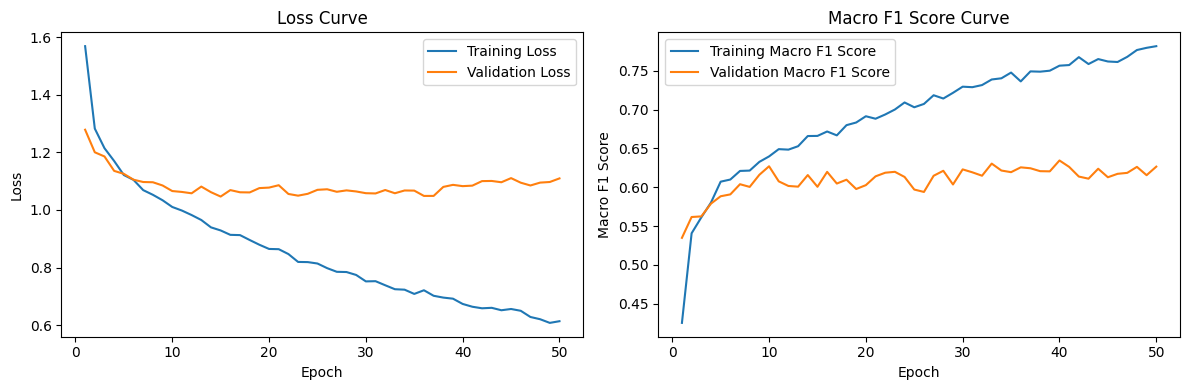

In [9]:
if __name__ == '__main__':
    model.load_weights("myguy.weights.h5")
    # Final evaluation
    val_loss, val_f1 = model.evaluate(val)
    print("Validation loss:", val_loss)
    print("Validation Macro F1:", val_f1)

    # Plot loss and Macro F1 curves
    epochs = range(1, len(history.history["loss"]) + 1)
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(epochs, history.history["loss"], label="Training Loss")
    plt.plot(epochs, history.history["val_loss"], label="Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Loss Curve")
    plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(epochs, history.history["f1_score"], label="Training Macro F1 Score")
    plt.plot(epochs, history.history["val_f1_score"], label="Validation Macro F1 Score")
    plt.xlabel("Epoch")
    plt.ylabel("Macro F1 Score")
    plt.title("Macro F1 Score Curve")
    plt.legend()
    plt.tight_layout()
    plt.show()

## Save the Model

If you are satisfied with your model's performance, you can customize the saving directory below and save your model checkpoint for testing.

**Model Performance Grading Criteria**

Public feedback is out of **100**: 60 points for functional tests and up to 40 for model performance. Final private grading after the deadline is out of **10**: 6 functional points and up to 4 performance points. Public and private scores are not added together.

Performance tiers are cumulative totals, not separate bonuses:
- Macro F1 below 0.57: public 0/40; private 0/4.
- Macro F1 at least 0.57 but below 0.59: public 10/40; private 1/4.
- Macro F1 at least 0.59 but below 0.61: public 20/40; private 2/4.
- Macro F1 at least 0.61: public 40/40; private 4/4.

### ZINC submission
Submit exactly **two files**:
1. `lab6_task.py`: in Colab choose **File → Download → Download .py**. Rename the exported file to `lab6_task.py`, even if you started from `lab6_tasks.ipynb`.
2. `model.weights.h5`: save weights from the same model architecture defined in your submitted Python file.

Deadline: **6 November 2026, 23:59 HKT**. Up to **50 submissions**; no late submission period. The last submission is used for final grading.
Run the notebook from top to bottom before exporting. Keep Drive mounting, dataset loading, training, and plotting under `if __name__ == "__main__":` so importing the submitted file does not execute them.


In [10]:
if __name__ == '__main__':
    save_path = Path('/content/drive/MyDrive/COMP2211/Lab6/model.weights.h5')
    model.save_weights(save_path)